In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

print("Libraries imported successfully!")

Libraries imported successfully!


In [ ]:
df = pd.read_csv('/content/Banglore_traffic_Dataset.csv')

print("Dataset loaded successfully!")

Dataset loaded successfully!


In [ ]:
df.head()

,Date,Area Name,Road/Intersection Name,Traffic Volume,Average Speed,Travel Time Index,Congestion Level,Road Capacity Utilization,Incident Reports,Environmental Impact,Public Transport Usage,Traffic Signal Compliance,Parking Usage,Pedestrian and Cyclist Count,Weather Conditions,Roadwork and Construction Activity
0,2022-01-01,Indiranagar,100 Feet Road,50590,50.230299,1.500000,100.000000,100.000000,0,151.180,70.632330,84.044600,85.403629,111,Clear,No
1,2022-01-01,Indiranagar,CMH Road,30825,29.377125,1.500000,100.000000,100.000000,1,111.650,41.924899,91.407038,59.983689,100,Clear,No
2,2022-01-01,Whitefield,Marathahalli Bridge,7399,54.474398,1.039069,28.347994,36.396525,0,64.798,44.662384,61.375541,95.466020,189,Clear,No
3,2022-01-01,Koramangala,Sony World Junction,60874,43.817610,1.500000,100.000000,100.000000,1,171.748,32.773123,75.547092,63.567452,111,Clear,No
4,2022-01-01,Koramangala,Sarjapur Road,57292,41.116763,1.500000,100.000000,100.000000,3,164.584,35.092601,64.634762,93.155171,104,Clear,No


In [ ]:
print("Number of rows:", df.shape[0])
print("Number of columns:", df.shape[1])

Number of rows: 8936
Number of columns: 16


In [ ]:
print(df.columns)

Index(['Date', 'Area Name', 'Road/Intersection Name', 'Traffic Volume',
       'Average Speed', 'Travel Time Index', 'Congestion Level',
       'Road Capacity Utilization', 'Incident Reports', 'Environmental Impact',
       'Public Transport Usage', 'Traffic Signal Compliance', 'Parking Usage',
       'Pedestrian and Cyclist Count', 'Weather Conditions',
       'Roadwork and Construction Activity'],
      dtype='object')


In [ ]:
df.isnull().sum()

,0
Date,0
Area Name,0
Road/Intersection Name,0
Traffic Volume,0
Average Speed,0
Travel Time Index,0
Congestion Level,0
Road Capacity Utilization,0
Incident Reports,0
Environmental Impact,0


In [ ]:
print("Number of duplicate rows:", df.duplicated().sum())

Number of duplicate rows: 0


In [ ]:
df.describe()

,Traffic Volume,Average Speed,Travel Time Index,Congestion Level,Road Capacity Utilization,Incident Reports,Environmental Impact,Public Transport Usage,Traffic Signal Compliance,Parking Usage,Pedestrian and Cyclist Count
count,8936.000000,8936.000000,8936.000000,8936.000000,8936.000000,8936.000000,8936.000000,8936.000000,8936.000000,8936.000000,8936.000000
mean,29236.048120,39.447427,1.375554,80.818041,92.029215,1.570389,108.472096,45.086651,79.950243,75.155597,114.533348
std,13001.808801,10.707244,0.165319,23.533182,16.583341,1.420047,26.003618,20.208460,11.585006,14.409394,36.812573
min,4233.000000,20.000000,1.000039,5.160279,18.739771,0.000000,58.466000,10.006853,60.003933,50.020411,66.000000
25%,19413.000000,31.775825,1.242459,64.292905,97.354990,0.000000,88.826000,27.341191,69.828270,62.545895,94.000000
50%,27600.000000,39.199368,1.500000,92.389018,100.000000,1.000000,105.200000,45.170684,79.992773,75.317610,102.000000
75%,38058.500000,46.644517,1.500000,100.000000,100.000000,2.000000,126.117000,62.426485,89.957358,87.518589,111.000000
max,72039.000000,89.790843,1.500000,100.000000,100.000000,10.000000,194.078000,79.979744,99.993652,99.995049,243.000000


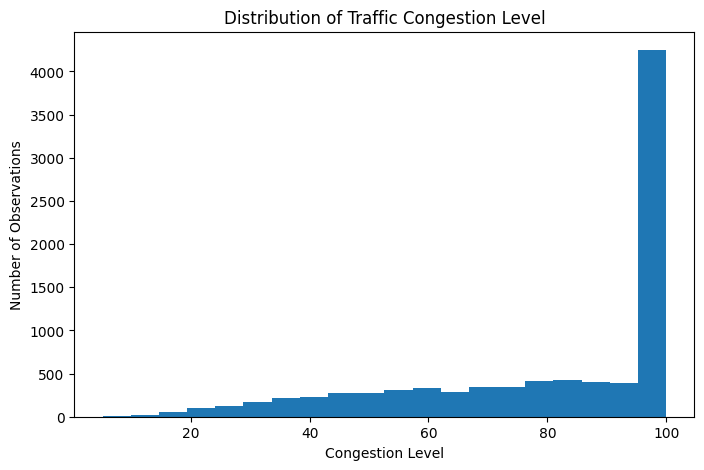

In [ ]:
plt.figure(figsize=(8,5))

plt.hist(df['Congestion Level'], bins=20)

plt.xlabel('Congestion Level')
plt.ylabel('Number of Observations')
plt.title('Distribution of Traffic Congestion Level')

plt.show()

In [ ]:
df['Area Name'].value_counts()

,count
Area Name,
Indiranagar,1720
M.G. Road,1501
Koramangala,1364
Jayanagar,1173
Hebbal,950
Whitefield,942
Yeshwanthpur,734
Electronic City,552


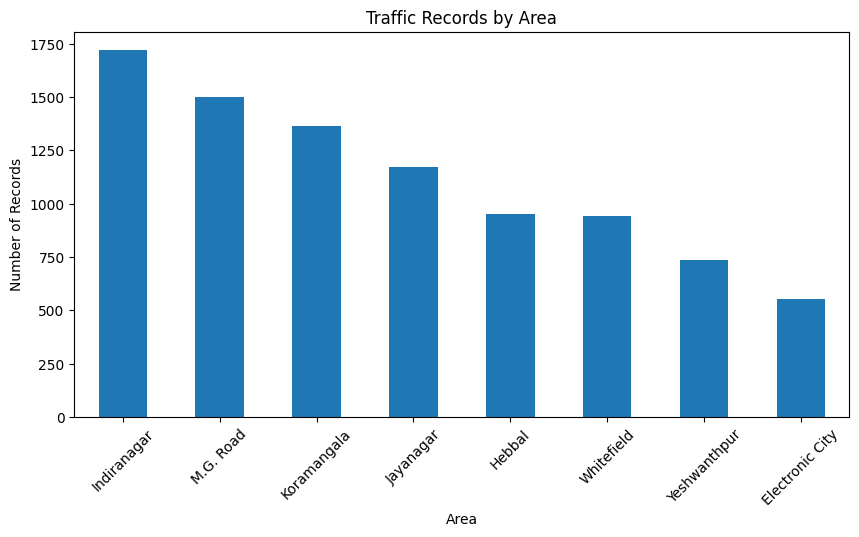

In [ ]:
plt.figure(figsize=(10,5))

df['Area Name'].value_counts().plot(kind='bar')

plt.xlabel('Area')
plt.ylabel('Number of Records')
plt.title('Traffic Records by Area')
plt.xticks(rotation=45)

plt.show()

In [ ]:
area_congestion = df.groupby('Area Name')['Congestion Level'].mean().sort_values(ascending=False)

print(area_congestion)

Area Name
Koramangala        93.985536
M.G. Road          90.579670
Indiranagar        87.641890
Hebbal             80.087244
Jayanagar          76.998324
Whitefield         69.054661
Yeshwanthpur       62.369634
Electronic City    54.454507
Name: Congestion Level, dtype: float64


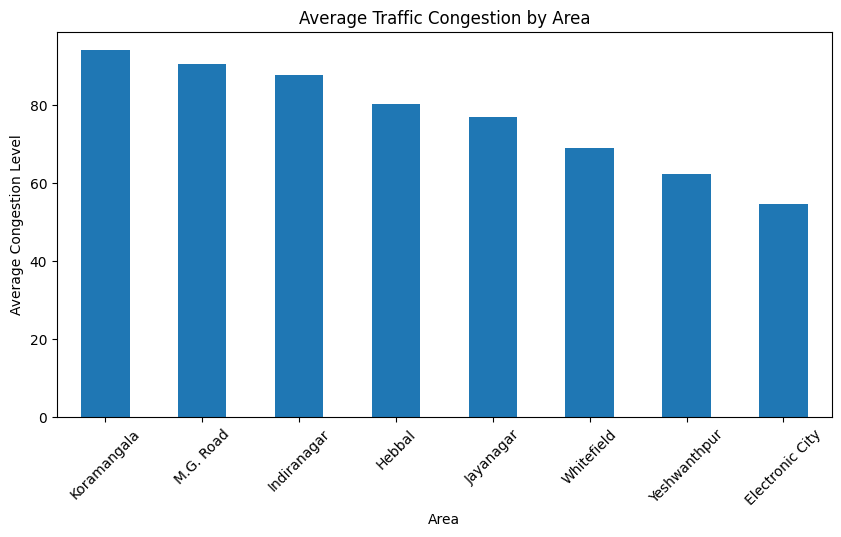

In [ ]:
plt.figure(figsize=(10,5))

area_congestion.plot(kind='bar')

plt.xlabel('Area')
plt.ylabel('Average Congestion Level')
plt.title('Average Traffic Congestion by Area')
plt.xticks(rotation=45)

plt.show()

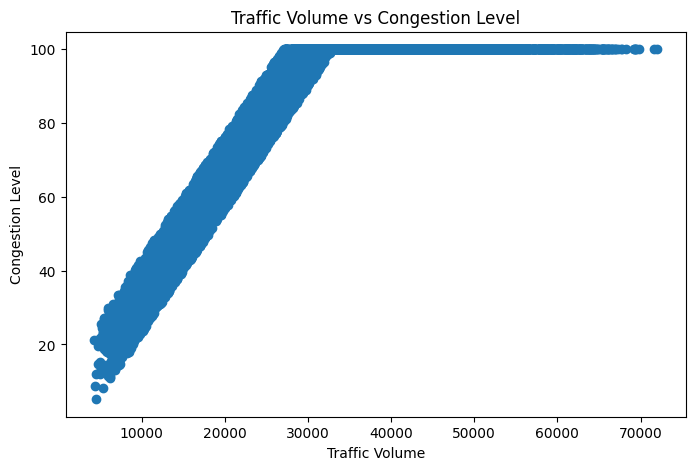

In [ ]:
plt.figure(figsize=(8,5))

plt.scatter(df['Traffic Volume'], df['Congestion Level'])

plt.xlabel('Traffic Volume')
plt.ylabel('Congestion Level')
plt.title('Traffic Volume vs Congestion Level')

plt.show()

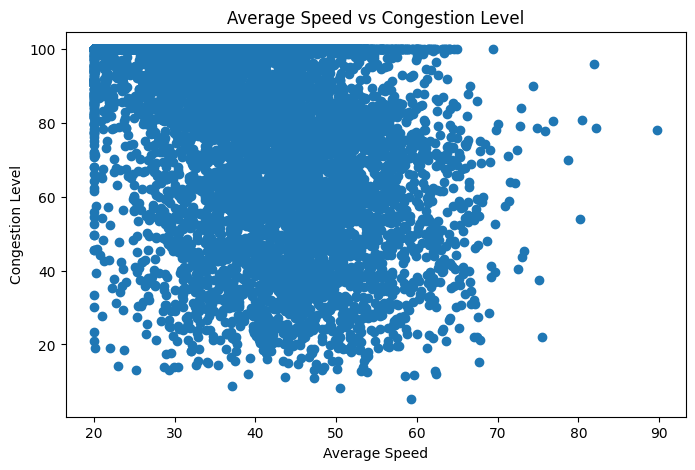

In [ ]:
plt.figure(figsize=(8,5))

plt.scatter(df['Average Speed'], df['Congestion Level'])

plt.xlabel('Average Speed')
plt.ylabel('Congestion Level')
plt.title('Average Speed vs Congestion Level')

plt.show()

In [ ]:
# Select numerical columns
numerical_data = df.select_dtypes(include=['number'])

# Calculate correlation with Congestion Level
correlation = numerical_data.corr()['Congestion Level'].sort_values(ascending=False)

print(correlation)

Congestion Level                1.000000
Road Capacity Utilization       0.865025
Environmental Impact            0.837218
Traffic Volume                  0.837218
Travel Time Index               0.751573
Incident Reports                0.418284
Traffic Signal Compliance       0.001810
Public Transport Usage         -0.002783
Parking Usage                  -0.025815
Average Speed                  -0.360250
Pedestrian and Cyclist Count   -0.738787
Name: Congestion Level, dtype: float64


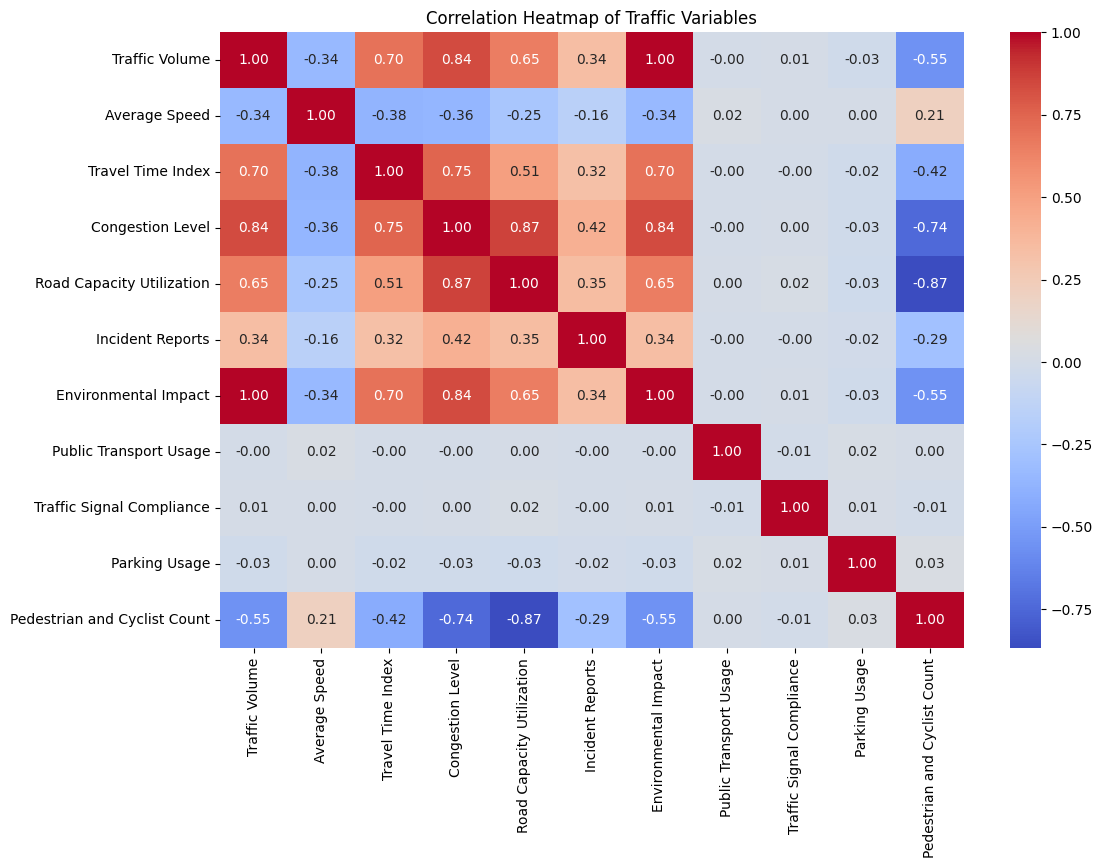

In [ ]:
import seaborn as sns

plt.figure(figsize=(12,8))

sns.heatmap(
    numerical_data.corr(),
    annot=True,
    cmap='coolwarm',
    fmt='.2f'
)

plt.title('Correlation Heatmap of Traffic Variables')
plt.show()

In [ ]:
print("Unique values in each column:")
print(df.nunique())

Unique values in each column:
Date                                   952
Area Name                                8
Road/Intersection Name                  16
Traffic Volume                        8100
Average Speed                         8572
Travel Time Index                     3711
Congestion Level                      5053
Road Capacity Utilization             2352
Incident Reports                        11
Environmental Impact                  8100
Public Transport Usage                8936
Traffic Signal Compliance             8936
Parking Usage                         8936
Pedestrian and Cyclist Count           148
Weather Conditions                       5
Roadwork and Construction Activity       2
dtype: int64


In [ ]:
print(df[['Traffic Volume',
          'Environmental Impact',
          'Congestion Level',
          'Road Capacity Utilization',
          'Travel Time Index']].head(10))

   Traffic Volume  Environmental Impact  Congestion Level  \
0           50590               151.180        100.000000   
1           30825               111.650        100.000000   
2            7399                64.798         28.347994   
3           60874               171.748        100.000000   
4           57292               164.584        100.000000   
5           47848               145.696        100.000000   
6           36574               123.148        100.000000   
7           25379               100.758         79.038823   
8           25022               100.044         78.979596   
9           31760               113.520         97.672462   

   Road Capacity Utilization  Travel Time Index  
0                 100.000000           1.500000  
1                 100.000000           1.500000  
2                  36.396525           1.039069  
3                 100.000000           1.500000  
4                 100.000000           1.500000  
5                 100.000000

In [ ]:
print(df[['Traffic Volume',
          'Environmental Impact',
          'Congestion Level',
          'Road Capacity Utilization',
          'Travel Time Index']].corr())

                           Traffic Volume  Environmental Impact  \
Traffic Volume                   1.000000              1.000000   
Environmental Impact             1.000000              1.000000   
Congestion Level                 0.837218              0.837218   
Road Capacity Utilization        0.652898              0.652898   
Travel Time Index                0.697514              0.697514   

                           Congestion Level  Road Capacity Utilization  \
Traffic Volume                     0.837218                   0.652898   
Environmental Impact               0.837218                   0.652898   
Congestion Level                   1.000000                   0.865025   
Road Capacity Utilization          0.865025                   1.000000   
Travel Time Index                  0.751573                   0.507774   

                           Travel Time Index  
Traffic Volume                      0.697514  
Environmental Impact                0.697514  
Congestion 

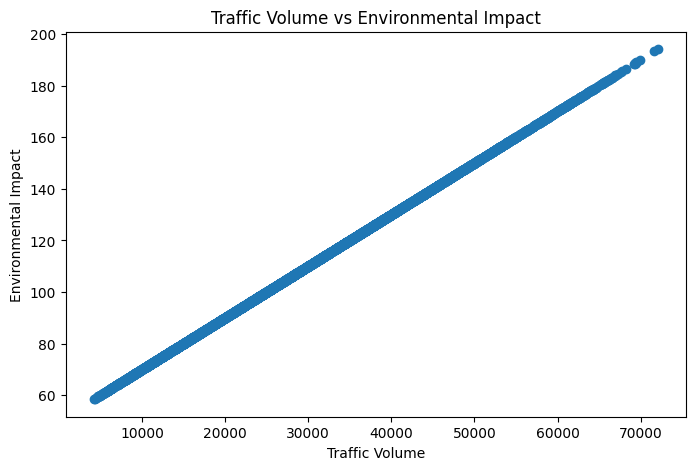

In [ ]:
plt.figure(figsize=(8,5))

plt.scatter(df['Traffic Volume'], df['Environmental Impact'])

plt.xlabel('Traffic Volume')
plt.ylabel('Environmental Impact')
plt.title('Traffic Volume vs Environmental Impact')

plt.show()

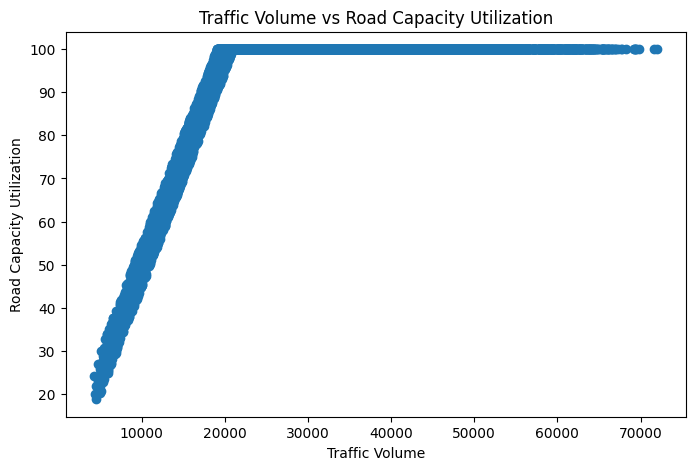

In [ ]:
plt.figure(figsize=(8,5))

plt.scatter(df['Traffic Volume'], df['Road Capacity Utilization'])

plt.xlabel('Traffic Volume')
plt.ylabel('Road Capacity Utilization')
plt.title('Traffic Volume vs Road Capacity Utilization')

plt.show()

In [ ]:
# Convert Date into datetime format
df['Date'] = pd.to_datetime(df['Date'])

# Extract useful date features
df['Day_of_Week'] = df['Date'].dt.dayofweek
df['Month'] = df['Date'].dt.month
df['Day'] = df['Date'].dt.day

print(df[['Date', 'Day_of_Week', 'Month', 'Day']].head())

        Date  Day_of_Week  Month  Day
0 2022-01-01            5      1    1
1 2022-01-01            5      1    1
2 2022-01-01            5      1    1
3 2022-01-01            5      1    1
4 2022-01-01            5      1    1


In [ ]:
print("Weather:")
print(df['Weather Conditions'].value_counts())

print("\nRoadwork:")
print(df['Roadwork and Construction Activity'].value_counts())

print("\nAreas:")
print(df['Area Name'].value_counts())

Weather:
Weather Conditions
Clear       5426
Overcast    1296
Fog          959
Rain         827
Windy        428
Name: count, dtype: int64

Roadwork:
Roadwork and Construction Activity
No     8054
Yes     882
Name: count, dtype: int64

Areas:
Area Name
Indiranagar        1720
M.G. Road          1501
Koramangala        1364
Jayanagar          1173
Hebbal              950
Whitefield          942
Yeshwanthpur        734
Electronic City     552
Name: count, dtype: int64


In [ ]:
print(df['Road/Intersection Name'].value_counts())

Road/Intersection Name
100 Feet Road          860
CMH Road               860
Anil Kumble Circle     759
Trinity Circle         742
Sony World Junction    684
Sarjapur Road          680
South End Circle       593
Jayanagar 4th Block    580
Marathahalli Bridge    492
Ballari Road           476
Hebbal Flyover         474
ITPL Main Road         450
Yeshwanthpur Circle    373
Tumkur Road            361
Hosur Road             277
Silk Board Junction    275
Name: count, dtype: int64


In [ ]:
print("Starting date:", df['Date'].min())
print("Ending date:", df['Date'].max())
print("Number of unique dates:", df['Date'].nunique())

Starting date: 2022-01-01 00:00:00
Ending date: 2024-08-09 00:00:00
Number of unique dates: 952


In [ ]:
print(df['Day_of_Week'].value_counts().sort_index())

Day_of_Week
0    1296
1    1309
2    1266
3    1250
4    1253
5    1290
6    1272
Name: count, dtype: int64


In [ ]:
weather_congestion = df.groupby(
    'Weather Conditions'
)['Congestion Level'].mean().sort_values(ascending=False)

print(weather_congestion)

Weather Conditions
Windy       82.369907
Fog         81.609357
Clear       80.723064
Rain        80.537699
Overcast    80.296523
Name: Congestion Level, dtype: float64


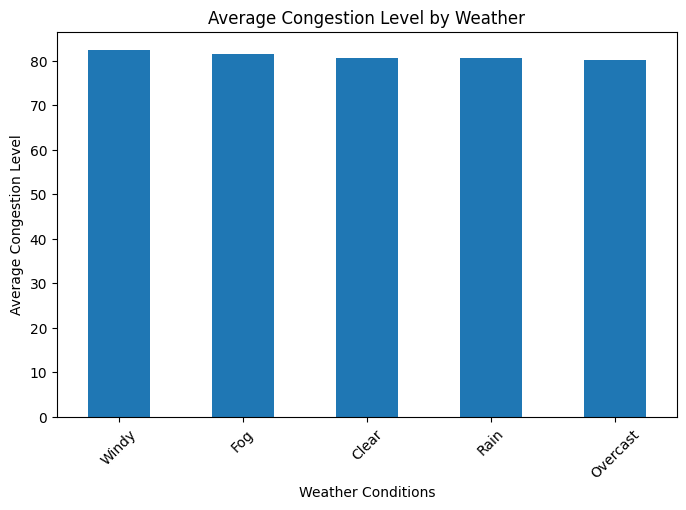

In [ ]:
plt.figure(figsize=(8,5))

weather_congestion.plot(kind='bar')

plt.xlabel('Weather Conditions')
plt.ylabel('Average Congestion Level')
plt.title('Average Congestion Level by Weather')

plt.xticks(rotation=45)
plt.show()

In [ ]:
roadwork_congestion = df.groupby(
    'Roadwork and Construction Activity'
)['Congestion Level'].mean()

print(roadwork_congestion)

Roadwork and Construction Activity
No     80.822195
Yes    80.780110
Name: Congestion Level, dtype: float64


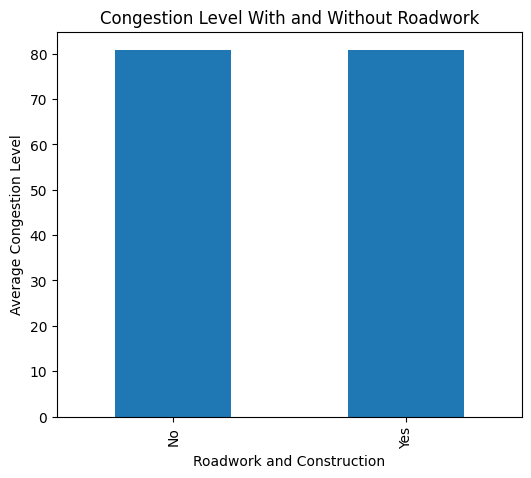

In [ ]:
plt.figure(figsize=(6,5))

roadwork_congestion.plot(kind='bar')

plt.xlabel('Roadwork and Construction')
plt.ylabel('Average Congestion Level')
plt.title('Congestion Level With and Without Roadwork')

plt.show()

In [ ]:
# Select the features for our first ML model

features = [
    'Traffic Volume',
    'Average Speed',
    'Travel Time Index',
    'Incident Reports',
    'Area Name',
    'Road/Intersection Name',
    'Weather Conditions',
    'Roadwork and Construction Activity',
    'Day_of_Week',
    'Month'
]

target = 'Congestion Level'

X = df[features]
y = df[target]

print("Features:")
print(X.columns.tolist())

print("\nTarget:")
print(target)

print("\nShape of X:", X.shape)
print("Shape of y:", y.shape)

Features:
['Traffic Volume', 'Average Speed', 'Travel Time Index', 'Incident Reports', 'Area Name', 'Road/Intersection Name', 'Weather Conditions', 'Roadwork and Construction Activity', 'Day_of_Week', 'Month']

Target:
Congestion Level

Shape of X: (8936, 10)
Shape of y: (8936,)


In [ ]:
X.head()

,Traffic Volume,Average Speed,Travel Time Index,Incident Reports,Area Name,Road/Intersection Name,Weather Conditions,Roadwork and Construction Activity,Day_of_Week,Month
0,50590,50.230299,1.500000,0,Indiranagar,100 Feet Road,Clear,No,5,1
1,30825,29.377125,1.500000,1,Indiranagar,CMH Road,Clear,No,5,1
2,7399,54.474398,1.039069,0,Whitefield,Marathahalli Bridge,Clear,No,5,1
3,60874,43.817610,1.500000,1,Koramangala,Sony World Junction,Clear,No,5,1
4,57292,41.116763,1.500000,3,Koramangala,Sarjapur Road,Clear,No,5,1


In [ ]:
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder

# Numerical columns
numerical_features = [
    'Traffic Volume',
    'Average Speed',
    'Travel Time Index',
    'Incident Reports',
    'Day_of_Week',
    'Month'
]

# Categorical columns
categorical_features = [
    'Area Name',
    'Road/Intersection Name',
    'Weather Conditions',
    'Roadwork and Construction Activity'
]

# Create preprocessing step
preprocessor = ColumnTransformer(
    transformers=[
        ('categorical', OneHotEncoder(handle_unknown='ignore'), categorical_features)
    ],
    remainder='passthrough'
)

print("Preprocessor created successfully!")

Preprocessor created successfully!


In [ ]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42
)

print("Training samples:", len(X_train))
print("Testing samples:", len(X_test))

Training samples: 7148
Testing samples: 1788


In [ ]:
from sklearn.pipeline import Pipeline
from sklearn.ensemble import RandomForestRegressor

# Create the Random Forest model
model = Pipeline(steps=[
    ('preprocessor', preprocessor),
    ('regressor', RandomForestRegressor(
        n_estimators=100,
        random_state=42,
        n_jobs=-1
    ))
])

# Train the model
model.fit(X_train, y_train)

print("Model trained successfully!")

Model trained successfully!


In [ ]:
y_pred = model.predict(X_test)

print("First 10 actual values:")
print(y_test.head(10).values)

print("\nFirst 10 predicted values:")
print(y_pred[:10])

First 10 actual values:
[100.         100.          79.10679882  73.84432891  59.95853717
  87.49441875  56.52723686  84.36322582  78.96183367 100.        ]

First 10 predicted values:
[100.         100.          79.58941864  76.87349184  56.93077879
  87.08904839  53.73368453  89.45634071  88.80983466 100.        ]


In [ ]:
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
import numpy as np

mae = mean_absolute_error(y_test, y_pred)
rmse = np.sqrt(mean_squared_error(y_test, y_pred))
r2 = r2_score(y_test, y_pred)

print("Model Performance")
print("-----------------")
print("MAE :", mae)
print("RMSE:", rmse)
print("R² Score:", r2)

Model Performance
-----------------
MAE : 2.8812930368418863
RMSE: 4.383504072416307
R² Score: 0.9644801316215916


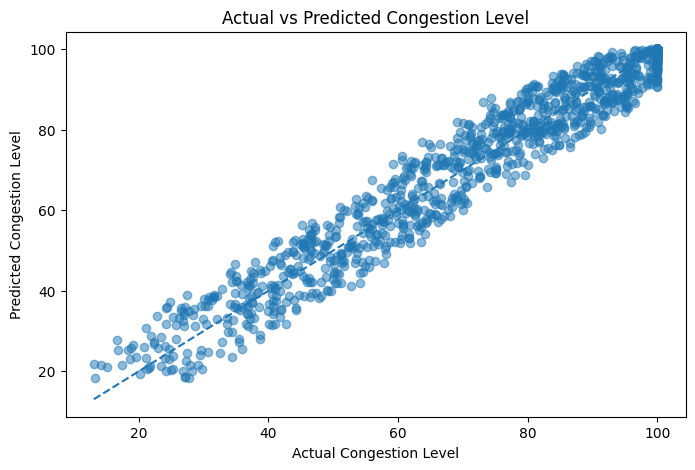

In [ ]:
plt.figure(figsize=(8,5))

plt.scatter(y_test, y_pred, alpha=0.5)

plt.xlabel('Actual Congestion Level')
plt.ylabel('Predicted Congestion Level')
plt.title('Actual vs Predicted Congestion Level')

plt.plot(
    [y_test.min(), y_test.max()],
    [y_test.min(), y_test.max()],
    linestyle='--'
)

plt.show()

In [ ]:
comparison = pd.DataFrame({
    'Actual': y_test.values,
    'Predicted': y_pred
})

comparison['Error'] = comparison['Actual'] - comparison['Predicted']

comparison.head(15)

,Actual,Predicted,Error
0,100.000000,100.000000,0.000000
1,100.000000,100.000000,0.000000
2,79.106799,79.589419,-0.482620
3,73.844329,76.873492,-3.029163
4,59.958537,56.930779,3.027758
5,87.494419,87.089048,0.405370
6,56.527237,53.733685,2.793552
7,84.363226,89.456341,-5.093115
8,78.961834,88.809835,-9.848001
9,100.000000,100.000000,0.000000


In [ ]:
# Features that can potentially be known before travelling

practical_features = [
    'Area Name',
    'Road/Intersection Name',
    'Day_of_Week',
    'Month',
    'Weather Conditions',
    'Roadwork and Construction Activity'
]

X_practical = df[practical_features]
y_practical = df['Congestion Level']

print("Practical features:")
print(X_practical.columns.tolist())

print("\nShape of X:", X_practical.shape)
print("Shape of y:", y_practical.shape)

Practical features:
['Area Name', 'Road/Intersection Name', 'Day_of_Week', 'Month', 'Weather Conditions', 'Roadwork and Construction Activity']

Shape of X: (8936, 6)
Shape of y: (8936,)


In [ ]:
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder

practical_categorical = [
    'Area Name',
    'Road/Intersection Name',
    'Weather Conditions',
    'Roadwork and Construction Activity'
]

practical_numerical = [
    'Day_of_Week',
    'Month'
]

practical_preprocessor = ColumnTransformer(
    transformers=[
        ('categorical',
         OneHotEncoder(handle_unknown='ignore'),
         practical_categorical)
    ],
    remainder='passthrough'
)

print("Practical preprocessor created!")

Practical preprocessor created!


In [ ]:
from sklearn.model_selection import train_test_split

X_train_p, X_test_p, y_train_p, y_test_p = train_test_split(
    X_practical,
    y_practical,
    test_size=0.2,
    random_state=42
)

print("Training samples:", len(X_train_p))
print("Testing samples:", len(X_test_p))

Training samples: 7148
Testing samples: 1788


In [ ]:
from sklearn.pipeline import Pipeline
from sklearn.ensemble import RandomForestRegressor

practical_model = Pipeline(steps=[
    ('preprocessor', practical_preprocessor),
    ('regressor', RandomForestRegressor(
        n_estimators=100,
        random_state=42,
        n_jobs=-1
    ))
])

practical_model.fit(X_train_p, y_train_p)

print("Practical model trained successfully!")

Practical model trained successfully!


In [ ]:
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
import numpy as np

y_pred_p = practical_model.predict(X_test_p)

mae_p = mean_absolute_error(y_test_p, y_pred_p)
rmse_p = np.sqrt(mean_squared_error(y_test_p, y_pred_p))
r2_p = r2_score(y_test_p, y_pred_p)

print("Practical Model Performance")
print("---------------------------")
print("MAE :", mae_p)
print("RMSE:", rmse_p)
print("R² Score:", r2_p)

Practical Model Performance
---------------------------
MAE : 17.066776835694274
RMSE: 22.53178464524775
R² Score: 0.061531494701079326
